# 🎬 IMDb Movie Rating Prediction

Predict a movie's IMDb rating from its **genre**, **release year** and **runtime**.

| Item | Details |
|---|---|
| Dataset | `IMDB-Movie-Data.csv` |
| Target | `Rating` |
| Features | `Genre` (multi-label), `Year`, `Runtime (Minutes)` |
| Models compared | Linear Regression, Decision Tree, Random Forest |
| Output | `movie_rating_model.pkl` (used by the separate Tkinter desktop app) |

**Notebook outline**

1. Setup
2. Load the data
3. Exploratory Data Analysis (EDA)
4. Data cleaning and preprocessing
5. Feature engineering and model preparation
6. Model training and evaluation
7. Saving the model

## 1. Setup

In [3]:
# Data handling and numerical computing
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine-learning tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Saving / loading the trained model
import joblib

## 2. Load the Data

In [4]:
# Location of the dataset (change this if your file is stored elsewhere,
# e.g. "/content/IMDB-Movie-Data.csv" in Colab or a Google Drive path)
DATA_PATH = "IMDB-Movie-Data.csv"

df = pd.read_csv(DATA_PATH)

In [5]:
# Preview the first 10 rows
df.head(10)

,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
0,1,Guardians of the Galaxy,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,James Gunn,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",2014,121,8.1,757074,333.13,76.0
1,2,Prometheus,"Adventure,Mystery,Sci-Fi","Following clues to the origin of mankind, a te...",Ridley Scott,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",2012,124,7.0,485820,126.46,65.0
2,3,Split,"Horror,Thriller",Three girls are kidnapped by a man with a diag...,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",2016,117,7.3,157606,138.12,62.0
3,4,Sing,"Animation,Comedy,Family","In a city of humanoid animals, a hustling thea...",Christophe Lourdelet,"Matthew McConaughey,Reese Witherspoon, Seth Ma...",2016,108,7.2,60545,270.32,59.0
4,5,Suicide Squad,"Action,Adventure,Fantasy",A secret government agency recruits some of th...,David Ayer,"Will Smith, Jared Leto, Margot Robbie, Viola D...",2016,123,6.2,393727,325.02,40.0
5,6,The Great Wall,"Action,Adventure,Fantasy",European mercenaries searching for black powde...,Yimou Zhang,"Matt Damon, Tian Jing, Willem Dafoe, Andy Lau",2016,103,6.1,56036,45.13,42.0
6,7,La La Land,"Comedy,Drama,Music",A jazz pianist falls for an aspiring actress i...,Damien Chazelle,"Ryan Gosling, Emma Stone, Rosemarie DeWitt, J....",2016,128,8.3,258682,151.06,93.0
7,8,Mindhorn,Comedy,A has-been actor best known for playing the ti...,Sean Foley,"Essie Davis, Andrea Riseborough, Julian Barrat...",2016,89,6.4,2490,NaN,71.0
8,9,The Lost City of Z,"Action,Adventure,Biography","A true-life drama, centering on British explor...",James Gray,"Charlie Hunnam, Robert Pattinson, Sienna Mille...",2016,141,7.1,7188,8.01,78.0
9,10,Passengers,"Adventure,Drama,Romance",A spacecraft traveling to a distant colony pla...,Morten Tyldum,"Jennifer Lawrence, Chris Pratt, Michael Sheen,...",2016,116,7.0,192177,100.01,41.0


## 3. Exploratory Data Analysis (EDA)

**Target variable:** `Rating`

We start by checking the structure and quality of the data, then look at how
the rating relates to genre, runtime and release year.

### 3.1 Dataset overview

In [6]:
# Number of rows and columns -> (rows, columns)
df.shape

(1000, 12)

In [7]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Rank                1000 non-null   int64  
 1   Title               1000 non-null   object 
 2   Genre               1000 non-null   object 
 3   Description         1000 non-null   object 
 4   Director            1000 non-null   object 
 5   Actors              1000 non-null   object 
 6   Year                1000 non-null   int64  
 7   Runtime (Minutes)   1000 non-null   int64  
 8   Rating              1000 non-null   float64
 9   Votes               1000 non-null   int64  
 10  Revenue (Millions)  872 non-null    float64
 11  Metascore           936 non-null    float64
dtypes: float64(3), int64(4), object(5)
memory usage: 93.9+ KB


In [8]:
# Column names only
df.columns

Index(['Rank', 'Title', 'Genre', 'Description', 'Director', 'Actors', 'Year',
       'Runtime (Minutes)', 'Rating', 'Votes', 'Revenue (Millions)',
       'Metascore'],
      dtype='object')

In [9]:
# Count of missing values in each column
df.isnull().sum()

,0
Rank,0
Title,0
Genre,0
Description,0
Director,0
Actors,0
Year,0
Runtime (Minutes),0
Rating,0
Votes,0


In [10]:
# Summary statistics (mean, std, min, quartiles, max) for numeric columns
df.describe()

,Rank,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
count,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,872.000000,936.000000
mean,500.500000,2012.783000,113.172000,6.723200,1.698083e+05,82.956376,58.985043
std,288.819436,3.205962,18.810908,0.945429,1.887626e+05,103.253540,17.194757
min,1.000000,2006.000000,66.000000,1.900000,6.100000e+01,0.000000,11.000000
25%,250.750000,2010.000000,100.000000,6.200000,3.630900e+04,13.270000,47.000000
50%,500.500000,2014.000000,111.000000,6.800000,1.107990e+05,47.985000,59.500000
75%,750.250000,2016.000000,123.000000,7.400000,2.399098e+05,113.715000,72.000000
max,1000.000000,2016.000000,191.000000,9.000000,1.791916e+06,936.630000,100.000000


### 3.2 Distribution of the target (`Rating`)

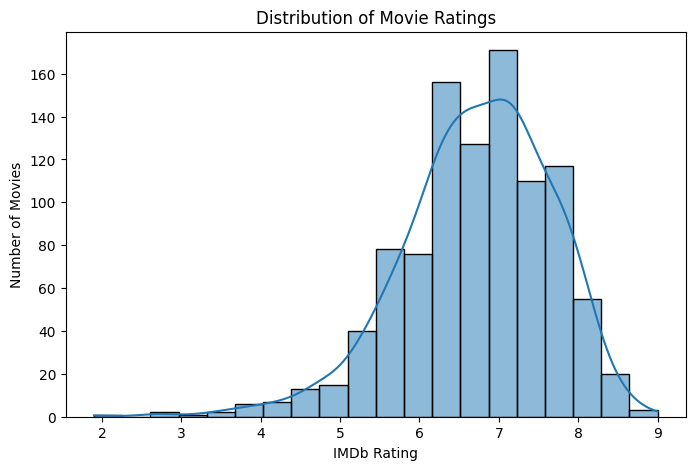

In [11]:
# Histogram with a KDE curve to see how ratings are distributed
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Rating"],
    bins=20,
    kde=True
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("IMDb Rating")
plt.ylabel("Number of Movies")

plt.show()

In [12]:
# Quick check of the distinct rating values for anything unexpected
df["Rating"].unique()

array([8.1, 7. , 7.3, 7.2, 6.2, 6.1, 8.3, 6.4, 7.1, 7.5, 7.8, 7.9, 7.7,
       6.6, 8.2, 6.7, 8. , 6.5, 5.3, 6.8, 4.7, 5.9, 6.3, 5.6, 8.6, 7.6,
       6.9, 2.7, 3.7, 5.8, 9. , 7.4, 4.1, 8.5, 8.8, 5.4, 6. , 5.7, 8.4,
       5.2, 5.5, 4.8, 3.9, 4.9, 5.1, 5. , 4.3, 4.6, 4.2, 4. , 3.2, 4.5,
       1.9, 3.5, 4.4])

### 3.3 Rating by genre

In the raw data each movie has a *combination* of genres (for example
`"Action,Adventure,Sci-Fi"`), so every unique combination is treated as its own
category in the first plot below. Later we split the combinations into
individual genres for a cleaner comparison.

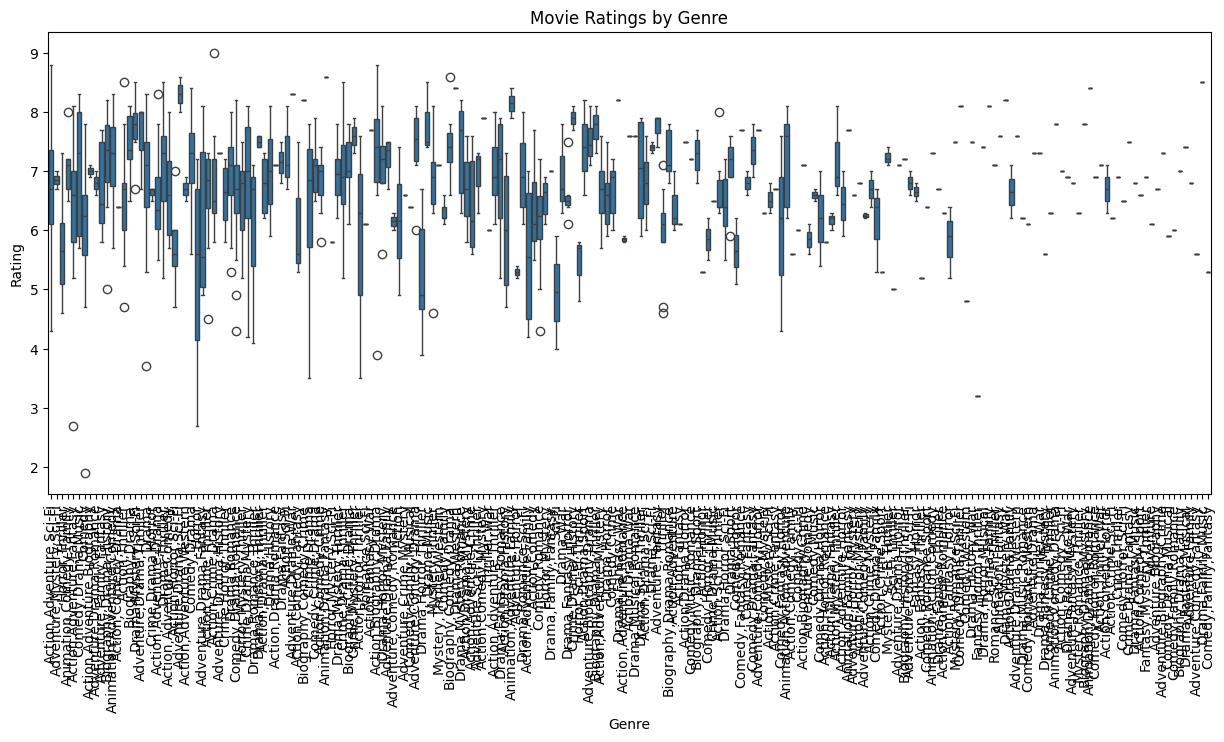

In [13]:
# Rating spread for each unique genre combination
# (many categories, so the x-axis labels are rotated)
plt.figure(figsize=(15, 6))

sns.boxplot(
    data=df,
    x="Genre",
    y="Rating"
)

plt.xticks(rotation=90)
plt.title("Movie Ratings by Genre")

plt.show()

In [14]:
# Unique genre combinations in the dataset
df["Genre"].unique()

array(['Action,Adventure,Sci-Fi', 'Adventure,Mystery,Sci-Fi',
       'Horror,Thriller', 'Animation,Comedy,Family',
       'Action,Adventure,Fantasy', 'Comedy,Drama,Music', 'Comedy',
       'Action,Adventure,Biography', 'Adventure,Drama,Romance',
       'Adventure,Family,Fantasy', 'Biography,Drama,History',
       'Animation,Adventure,Comedy', 'Action,Comedy,Drama',
       'Action,Thriller', 'Biography,Drama', 'Drama,Mystery,Sci-Fi',
       'Adventure,Drama,Thriller', 'Drama', 'Crime,Drama,Horror',
       'Action,Adventure,Drama', 'Drama,Thriller',
       'Action,Adventure,Comedy', 'Action,Horror,Sci-Fi',
       'Adventure,Drama,Sci-Fi', 'Action,Adventure,Western',
       'Comedy,Drama', 'Horror', 'Adventure,Drama,Fantasy',
       'Action,Crime,Thriller', 'Action,Crime,Drama',
       'Adventure,Drama,History', 'Crime,Horror,Thriller',
       'Drama,Romance', 'Comedy,Drama,Romance', 'Horror,Mystery,Thriller',
       'Crime,Drama,Mystery', 'Drama,Romance,Thriller',
       'Drama,History,T

In [15]:
# How many movies fall under each genre combination (missing values included)
df["Genre"].value_counts(dropna=False)

,count
Genre,
"Action,Adventure,Sci-Fi",50
Drama,48
"Comedy,Drama,Romance",35
Comedy,32
"Drama,Romance",31
...,...
"Drama,Fantasy,Musical",1
"Adventure,Family",1
"Adventure,Comedy,Fantasy",1


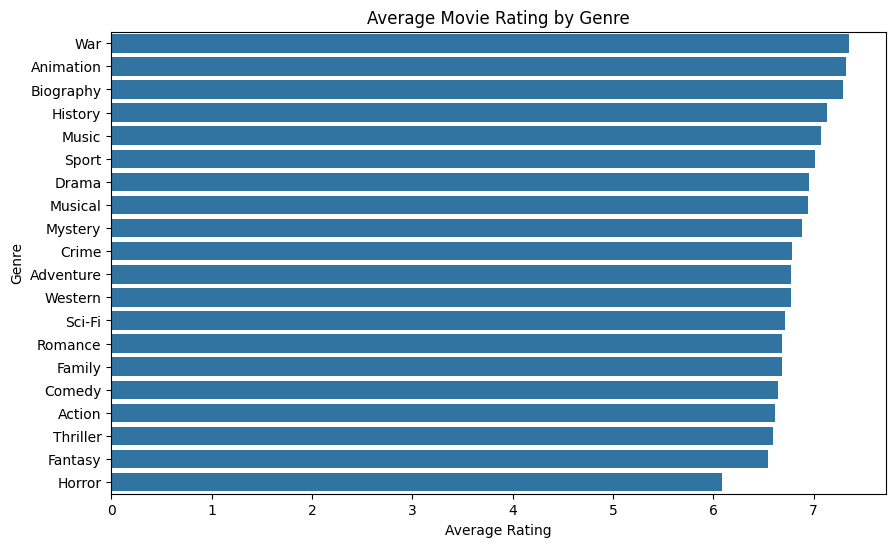

In [16]:
# Split "Action,Adventure,Sci-Fi" into separate rows, one per genre,
# so each individual genre can be analysed on its own
genre_df = df.assign(
    Genre=df["Genre"].str.split(",")
).explode("Genre")

# Remove any leading/trailing spaces left over from the split
genre_df["Genre"] = genre_df["Genre"].str.strip()

# Average rating for each individual genre, highest first
genre_rating = (
    genre_df.groupby("Genre")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

# Horizontal bar chart of the average rating per genre
plt.figure(figsize=(10, 6))

sns.barplot(
    x=genre_rating.values,
    y=genre_rating.index
)

plt.title("Average Movie Rating by Genre")
plt.xlabel("Average Rating")
plt.ylabel("Genre")

plt.show()

### 3.4 Rating vs runtime

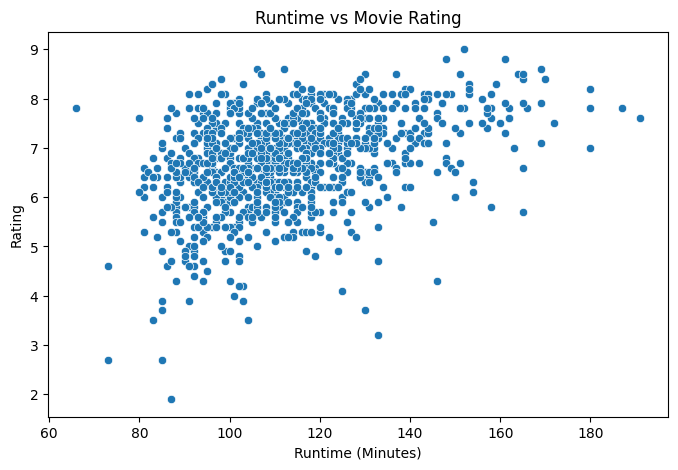

In [17]:
# Does a longer movie tend to get a higher or lower rating?
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Runtime (Minutes)",
    y="Rating"
)

plt.title("Runtime vs Movie Rating")
plt.show()

### 3.5 Rating vs release year

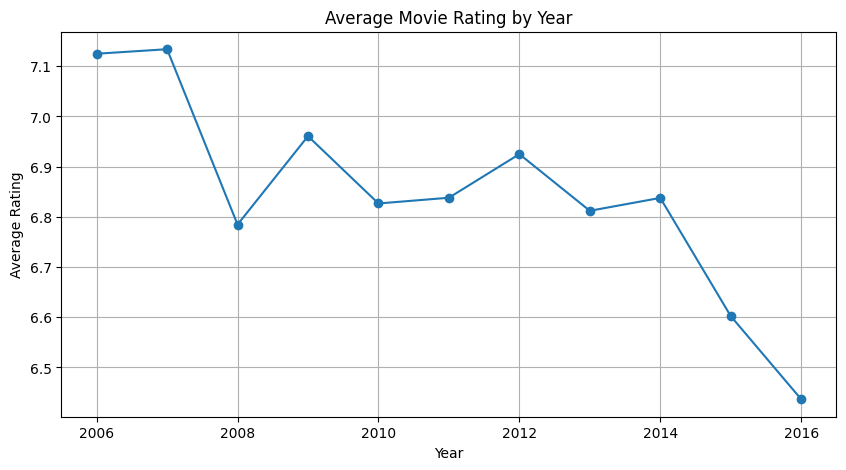

In [18]:
# Average rating for each release year
year_rating = df.groupby("Year")["Rating"].mean()

# Line chart showing how the average rating changes over time
plt.figure(figsize=(10, 5))

year_rating.plot(kind="line", marker="o")

plt.title("Average Movie Rating by Year")
plt.xlabel("Year")
plt.ylabel("Average Rating")
plt.grid(True)

plt.show()

In [19]:
# Number of movies released in each year
df["Year"].value_counts(dropna=False)

,count
Year,
2016,297
2015,127
2014,98
2013,91
2012,64
2011,63
2010,60
2007,53
2008,52


## 4. Data Cleaning and Preprocessing

With the data understood, we now prepare it for machine learning: keep only
the columns we need, make sure they have the right data types, and turn the
genre text into lists.

In [20]:
# Keep only the columns used for modelling
# (.copy() avoids pandas "SettingWithCopy" warnings when we edit it later)
df_model = df[
    ["Genre", "Year", "Runtime (Minutes)", "Rating"]
].copy()

df_model.head()

,Genre,Year,Runtime (Minutes),Rating
0,"Action,Adventure,Sci-Fi",2014,121,8.1
1,"Adventure,Mystery,Sci-Fi",2012,124,7.0
2,"Horror,Thriller",2016,117,7.3
3,"Animation,Comedy,Family",2016,108,7.2
4,"Action,Adventure,Fantasy",2016,123,6.2


In [21]:
# Confirm that none of the selected columns have missing values
df_model.isnull().sum()

,0
Genre,0
Year,0
Runtime (Minutes),0
Rating,0


In [22]:
# Inspect the release years in sorted order to spot any unusual values
np.sort(df_model["Year"].unique())

array([2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016])

In [23]:
# Make sure the numeric columns are really numeric.
# errors="coerce" turns any invalid entry into NaN instead of raising an error.
numeric_columns = ["Year", "Runtime (Minutes)", "Rating"]

for column in numeric_columns:
    df_model[column] = pd.to_numeric(
        df_model[column],
        errors="coerce"
    )

df_model.head()

,Genre,Year,Runtime (Minutes),Rating
0,"Action,Adventure,Sci-Fi",2014,121,8.1
1,"Adventure,Mystery,Sci-Fi",2012,124,7.0
2,"Horror,Thriller",2016,117,7.3
3,"Animation,Comedy,Family",2016,108,7.2
4,"Action,Adventure,Fantasy",2016,123,6.2


In [24]:
# Re-check for missing values after the type conversion
# (any NaN here would mean a value could not be converted to a number)
df_model.isnull().sum()

,0
Genre,0
Year,0
Runtime (Minutes),0
Rating,0


In [25]:
# Convert each genre string into a list of genres,
# e.g. "Action, Adventure" -> ["Action", "Adventure"]
df_model["Genre"] = df_model["Genre"].apply(
    lambda x: [g.strip() for g in x.split(",")]
)

df_model["Genre"].head()

,Genre
0,"[Action, Adventure, Sci-Fi]"
1,"[Adventure, Mystery, Sci-Fi]"
2,"[Horror, Thriller]"
3,"[Animation, Comedy, Family]"
4,"[Action, Adventure, Fantasy]"


In [26]:
# Final check of data types and shape before modelling
print(df_model.dtypes)
print()
print("Shape:", df_model.shape)

Genre                 object
Year                   int64
Runtime (Minutes)      int64
Rating               float64
dtype: object

Shape: (1000, 4)


## 5. Feature Engineering and Model Preparation

### 5.1 Separate inputs (X) and output (y)

In [27]:
# Input features
X = df_model[
    ["Genre", "Year", "Runtime (Minutes)"]
]

# Target we want to predict
y = df_model["Rating"]

In [28]:
# Peek at the inputs and the target
X.head()

,Genre,Year,Runtime (Minutes)
0,"[Action, Adventure, Sci-Fi]",2014,121
1,"[Adventure, Mystery, Sci-Fi]",2012,124
2,"[Horror, Thriller]",2016,117
3,"[Animation, Comedy, Family]",2016,108
4,"[Action, Adventure, Fantasy]",2016,123


In [29]:
y.head()

,Rating
0,8.1
1,7.0
2,7.3
3,7.2
4,6.2


### 5.2 Train / test split

80% of the data is used for training and 20% is held back for testing.
`random_state=42` makes the split reproducible.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [31]:
print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape:  {X_test.shape}")

Training data shape: (800, 3)
Testing data shape:  (200, 3)


### 5.3 Encode the genres

Models need numbers, not lists of text. `MultiLabelBinarizer` creates one
0/1 column per genre, so a movie tagged *Action* and *Sci-Fi* gets a `1` in
both of those columns.

The encoder is **fitted on the training data only** and then applied to the
test data, so no information from the test set leaks into training.

In [32]:
# Create the encoder
mlb = MultiLabelBinarizer()

# Learn the genre list from the training data and encode it
X_train_genre = mlb.fit_transform(X_train["Genre"])

# Encode the test data using the genres learned from training
X_test_genre = mlb.transform(X_test["Genre"])

In [33]:
# Wrap the encoded arrays in DataFrames (one column per genre).
# Reusing the original index keeps rows aligned with the other features.
train_genre_df = pd.DataFrame(
    X_train_genre,
    columns=mlb.classes_,
    index=X_train.index
)

test_genre_df = pd.DataFrame(
    X_test_genre,
    columns=mlb.classes_,
    index=X_test.index
)

In [34]:
# Numeric features only (the original Genre column is replaced by the encoded one)
X_train_num = X_train.drop(columns=["Genre"])
X_test_num = X_test.drop(columns=["Genre"])

### 5.4 Combine numeric and encoded features

In [35]:
# Join the numeric columns and the genre columns side by side (axis=1 -> column-wise)
X_train_final = pd.concat(
    [X_train_num, train_genre_df],
    axis=1
)

X_test_final = pd.concat(
    [X_test_num, test_genre_df],
    axis=1
)

## 6. Model Training and Evaluation

We train three different algorithms, compare their performance and pick the
one that works best for this dataset.

**Metrics used**

- **MAE**: average absolute error (in rating points)
- **MSE**: average squared error (penalizes large mistakes more)
- **RMSE**: square root of MSE (same units as the rating)
- **R² score**: share of the variance explained by the model (closer to 1 is better)

### 6.1 Model 1: Linear Regression

In [36]:
# Create the model
lr_model = LinearRegression()

# Train on the training data
lr_model.fit(X_train_final, y_train)

# Predict ratings for the test data
lr_predictions = lr_model.predict(X_test_final)

# Show the first 10 predictions
print(lr_predictions[:10])

[6.9513233  7.11057013 6.1984578  6.73787318 6.79740978 6.28554484
 6.45804582 6.75684882 8.20290998 7.3526694 ]


In [37]:
# Evaluate Linear Regression on the test set
mae = mean_absolute_error(y_test, lr_predictions)
mse = mean_squared_error(y_test, lr_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
MAE: 0.6225048103288784
MSE: 0.7128699175043309
RMSE: 0.8443162425917974
R2 Score: 0.25631474006500243


### 6.2 Model 2: Decision Tree

In [38]:
# max_depth=5 limits tree growth to reduce overfitting
dt_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=5
)

# Train
dt_model.fit(X_train_final, y_train)

# Predict
dt_predictions = dt_model.predict(X_test_final)

### 6.3 Model 3: Random Forest

In [39]:
# An ensemble of 200 decision trees; averaging them gives more stable predictions
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

# Train
rf_model.fit(X_train_final, y_train)

# Predict
rf_predictions = rf_model.predict(X_test_final)

### 6.4 Compare the models

In [40]:
# Predictions from each model, keyed by model name
models = {
    "Linear Regression": lr_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions
}

# Calculate every metric for each model
results = []

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Show the results side by side
results_df = pd.DataFrame(results)

print(results_df)

               Model       MAE       MSE      RMSE  R2 Score
0  Linear Regression  0.622505  0.712870  0.844316  0.256315
1      Decision Tree  0.632316  0.731862  0.855490  0.236501
2      Random Forest  0.589135  0.641677  0.801047  0.330585


### 6.5 Actual vs predicted ratings (Random Forest)

Points close to the dashed diagonal line are accurate predictions.

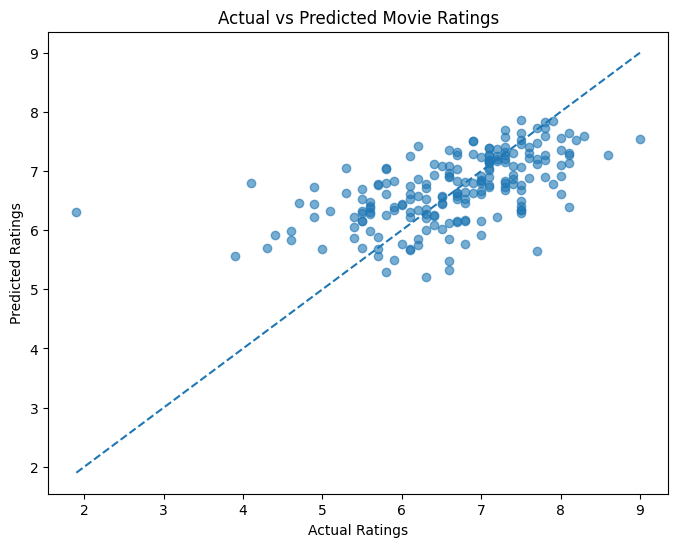

In [41]:
plt.figure(figsize=(8, 6))

# Each point is one test movie: actual rating (x) vs predicted rating (y)
plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.6
)

plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")
plt.title("Actual vs Predicted Movie Ratings")

# Dashed line = perfect predictions (predicted equals actual)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

## 7. Save the Model

The Random Forest model, the genre encoder and the exact feature-column order
are saved together in one file. The desktop app needs all three to turn user input into
the same format the model was trained on.

> **Tip:** load this file with the same scikit-learn version that was used to
> save it. A different version shows an `InconsistentVersionWarning` and may
> give slightly different results.

In [42]:
# Bundle everything the app needs into a single dictionary
model_data = {
    "model": rf_model,
    "encoder": mlb,
    "feature_columns": X_train_final.columns.tolist()
}

# Save to disk
joblib.dump(model_data, "movie_rating_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [43]:
# Sanity check: make sure the saved file loads back correctly
loaded_data = joblib.load("movie_rating_model.pkl")

loaded_model = loaded_data["model"]
loaded_encoder = loaded_data["encoder"]

print("Model loaded successfully!")

Model loaded successfully!
